# Train EfficientNetV2-S — Brain MRI Classification

This notebook trains EfficientNetV2-S and saves the best checkpoint. **Training only happens when you run cells in this notebook.**

**Prerequisites**
- Run your data-preparation notebook first.
- It must have created `prepared_data/train.csv`, `prepared_data/validation.csv`, and `prepared_data/test.csv`.
- Each CSV must contain at least the columns `filepath` and `class`.

The CSVs contain paths to the images; do not move the image dataset after creating the splits unless you update those paths.

## 1. Imports and configuration

If needed, uncomment the installation command and run it once. Pretrained weights may need to be downloaded the first time the model is created.

In [1]:
# %pip install pandas pillow matplotlib scikit-learn torch torchvision

from pathlib import Path
import copy
import random
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import efficientnet_v2_s, EfficientNet_V2_S_Weights

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DATA_DIR = Path("prepared_data")
MODEL_DIR = Path("trained_models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

TRAIN_CSV = DATA_DIR / "train.csv"
VAL_CSV = DATA_DIR / "validation.csv"
TEST_CSV = DATA_DIR / "test.csv"

CHECKPOINT_PATH = MODEL_DIR / "efficientnet_v2_s_best.pth"
HISTORY_PATH = MODEL_DIR / "efficientnet_v2_s_training_history.csv"

BATCH_SIZE = 8 if not torch.cuda.is_available() else 16
HEAD_EPOCHS = 3
FINETUNE_EPOCHS = 7

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
print("Batch size:", BATCH_SIZE)

c:\Users\rickv\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
c:\Users\rickv\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


Device: cuda
Batch size: 16


## 2. Load the saved splits

This notebook does not recreate or change the split. It uses the CSVs saved during data preparation.

In [2]:
for csv_path in [TRAIN_CSV, VAL_CSV, TEST_CSV]:
    if not csv_path.exists():
        raise FileNotFoundError(
            f"Missing {csv_path}. Run the data-preparation notebook first "
            "and check that its output folder is named 'prepared_data'."
        )

train_df = pd.read_csv(TRAIN_CSV)
val_df = pd.read_csv(VAL_CSV)
test_df = pd.read_csv(TEST_CSV)

required_columns = {"filepath", "class"}
for name, frame in [
    ("train", train_df), ("validation", val_df), ("test", test_df)
]:
    missing = required_columns - set(frame.columns)
    if missing:
        raise ValueError(f"{name}.csv is missing columns: {sorted(missing)}")

class_names = sorted(train_df["class"].unique().tolist())
class_to_idx = {name: i for i, name in enumerate(class_names)}
idx_to_class = {i: name for name, i in class_to_idx.items()}

# Ensure all splits contain only the same four known classes.
for name, frame in [("validation", val_df), ("test", test_df)]:
    unknown = set(frame["class"].unique()) - set(class_names)
    if unknown:
        raise ValueError(f"Unexpected classes in {name}: {unknown}")

print("Classes:", class_to_idx)
print(f"Train: {len(train_df)} | Validation: {len(val_df)} | Test: {len(test_df)}")
display(pd.DataFrame({
    "train": train_df["class"].value_counts(),
    "validation": val_df["class"].value_counts(),
    "test": test_df["class"].value_counts()
}).fillna(0).astype(int).sort_index())

Classes: {'glioma_tumor': 0, 'meningioma_tumor': 1, 'normal': 2, 'pituitary_tumor': 3}
Train: 1991 | Validation: 427 | Test: 427


,train,validation,test
class,,,
glioma_tumor,619,133,133
meningioma_tumor,571,122,123
normal,217,47,46
pituitary_tumor,584,125,125


## 3. Create datasets and dataloaders

Training uses a small random rotation as augmentation. Validation and test images are not randomly augmented.

In [3]:
weights = EfficientNet_V2_S_Weights.DEFAULT

train_transform = transforms.Compose([
    transforms.Resize((384, 384)),
    transforms.RandomRotation(degrees=5),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])
eval_transform = weights.transforms()

class BrainMRIDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True).copy()
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]
        with Image.open(row["filepath"]) as img:
            image = img.convert("RGB")
        label = class_to_idx[row["class"]]
        if self.transform:
            image = self.transform(image)
        return image, label

train_dataset = BrainMRIDataset(train_df, train_transform)
val_dataset = BrainMRIDataset(val_df, eval_transform)
test_dataset = BrainMRIDataset(test_df, eval_transform)

generator = torch.Generator().manual_seed(SEED)

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=0, generator=generator
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0
)

batch_images, batch_labels = next(iter(train_loader))
print("Training batch shape:", tuple(batch_images.shape))
print("Label batch shape:", tuple(batch_labels.shape))

Training batch shape: (16, 3, 384, 384)
Label batch shape: (16,)


## 4. Build EfficientNetV2-S

The pretrained feature extractor is initially frozen. The first phase trains only the final classification layer; the second phase fine-tunes the full network.

In [4]:
model = efficientnet_v2_s(weights=weights)
model.classifier[1] = nn.Linear(
    model.classifier[1].in_features, len(class_names)
)
model = model.to(device)

criterion = nn.CrossEntropyLoss()
print(model.classifier)

Sequential(
  (0): Dropout(p=0.2, inplace=True)
  (1): Linear(in_features=1280, out_features=4, bias=True)
)


## 5. Training loop

Run this cell to train. It saves a checkpoint whenever validation loss improves. Re-running this cell will train again, so run it only when you intend to retrain.

In [5]:
history = []
best_val_loss = float("inf")
best_model_weights = copy.deepcopy(model.state_dict())

def run_training_phase(optimizer, epochs, phase_name):
    global best_val_loss, best_model_weights

    for epoch in range(epochs):
        epoch_start = time.time()

        model.train()
        train_loss_sum = 0.0
        train_correct = 0
        train_count = 0

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            train_loss_sum += loss.item() * labels.size(0)
            train_correct += (outputs.argmax(dim=1) == labels).sum().item()
            train_count += labels.size(0)

        train_loss = train_loss_sum / train_count
        train_acc = train_correct / train_count

        model.eval()
        val_loss_sum = 0.0
        val_correct = 0
        val_count = 0

        with torch.no_grad():
            for images, labels in val_loader:
                images = images.to(device)
                labels = labels.to(device)
                outputs = model(images)
                loss = criterion(outputs, labels)

                val_loss_sum += loss.item() * labels.size(0)
                val_correct += (outputs.argmax(dim=1) == labels).sum().item()
                val_count += labels.size(0)

        val_loss = val_loss_sum / val_count
        val_acc = val_correct / val_count

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_model_weights = copy.deepcopy(model.state_dict())
            torch.save({
                "model_state_dict": best_model_weights,
                "class_names": class_names,
                "class_to_idx": class_to_idx,
                "architecture": "efficientnet_v2_s",
                "input_size": 384,
                "best_val_loss": best_val_loss,
                "seed": SEED
            }, CHECKPOINT_PATH)

        record = {
            "phase": phase_name,
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "train_accuracy": train_acc,
            "val_loss": val_loss,
            "val_accuracy": val_acc,
            "seconds": time.time() - epoch_start
        }
        history.append(record)

        print(
            f"{phase_name} | Epoch {epoch + 1}/{epochs} | "
            f"train loss {train_loss:.4f}, acc {train_acc:.4f} | "
            f"val loss {val_loss:.4f}, acc {val_acc:.4f} | "
            f"{record['seconds']:.1f}s"
        )

# Phase 1: train only the classifier
for parameter in model.features.parameters():
    parameter.requires_grad = False

head_optimizer = optim.AdamW(
    model.classifier.parameters(), lr=1e-3, weight_decay=1e-4
)
run_training_phase(head_optimizer, HEAD_EPOCHS, "Frozen backbone")

# Phase 2: fine-tune all layers with a smaller learning rate
for parameter in model.features.parameters():
    parameter.requires_grad = True

finetune_optimizer = optim.AdamW(
    model.parameters(), lr=1e-4, weight_decay=1e-4
)
run_training_phase(finetune_optimizer, FINETUNE_EPOCHS, "Fine-tuning")

pd.DataFrame(history).to_csv(HISTORY_PATH, index=False)
print("\nTraining finished.")
print("Best checkpoint:", CHECKPOINT_PATH.resolve())
print("Training history:", HISTORY_PATH.resolve())

Frozen backbone | Epoch 1/3 | train loss 0.9806, acc 0.6328 | val loss 0.8029, acc 0.7166 | 42.0s
Frozen backbone | Epoch 2/3 | train loss 0.7289, acc 0.7343 | val loss 0.6987, acc 0.7447 | 39.1s
Frozen backbone | Epoch 3/3 | train loss 0.6854, acc 0.7428 | val loss 0.6461, acc 0.7564 | 38.7s
Fine-tuning | Epoch 1/7 | train loss 0.3946, acc 0.8553 | val loss 0.2176, acc 0.9227 | 361.2s
Fine-tuning | Epoch 2/7 | train loss 0.1810, acc 0.9342 | val loss 0.1957, acc 0.9321 | 348.9s
Fine-tuning | Epoch 3/7 | train loss 0.0898, acc 0.9704 | val loss 0.1806, acc 0.9391 | 347.1s
Fine-tuning | Epoch 4/7 | train loss 0.0588, acc 0.9814 | val loss 0.2227, acc 0.9344 | 389.3s
Fine-tuning | Epoch 5/7 | train loss 0.0475, acc 0.9869 | val loss 0.2546, acc 0.9461 | 301.0s
Fine-tuning | Epoch 6/7 | train loss 0.0607, acc 0.9784 | val loss 0.1965, acc 0.9461 | 287.6s
Fine-tuning | Epoch 7/7 | train loss 0.0293, acc 0.9895 | val loss 0.2348, acc 0.9485 | 290.1s

Training finished.
Best checkpoint: C:\U

## 6. View training history

This plots the history from the current run. It does not train the model.

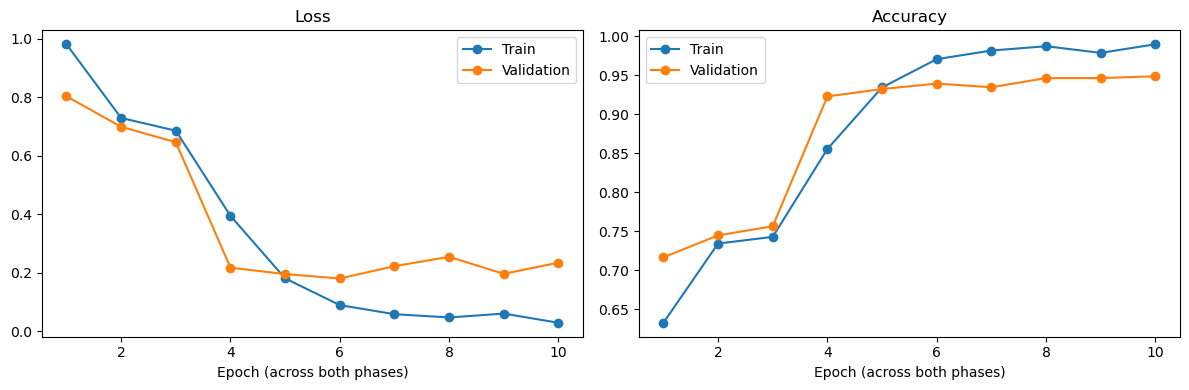

In [6]:
history_df = pd.DataFrame(history)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history_df.index + 1, history_df["train_loss"], marker="o", label="Train")
axes[0].plot(history_df.index + 1, history_df["val_loss"], marker="o", label="Validation")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch (across both phases)")
axes[0].legend()

axes[1].plot(history_df.index + 1, history_df["train_accuracy"], marker="o", label="Train")
axes[1].plot(history_df.index + 1, history_df["val_accuracy"], marker="o", label="Validation")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch (across both phases)")
axes[1].legend()

plt.tight_layout()
plt.show()